# Fig 7. Medellín against Bogotá

Fig 7: Medellin against Bogota. (a) pipeline LOYO R2 bars (pooled, SFS+NN pipeline
scores, NOT the equations); (b) which physical roles appear in each robust core.

**Review fixes (2026-09-21):** (R5) Bogotá O3's column now reads the falsification front
(`bogota_o3_temp_falsification_pareto.csv`), the front the lead O3 equation actually came from,
so `temp_2m` and `w700` are no longer missing from its core just because the original-pool front
never had temperature as a candidate. (R4) Medellín's pooled R2 in panel (a) is annotated with the
much lower mean-of-per-year R2 (0.097 PM2.5, 0.285 O3, from notebook A2's SI table): most of
Medellín PM2.5's apparent pooled skill is between-year differences in level, not within-year
predictive skill, and panel (a) alone would overstate it.

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()          # notebooks/ folder
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from termmap_utils import DATA, load_front, term_presence, term_summary
from style import *   # PM25, O3, NAVY, GREY, RED, LIGHT, ROOT, DATA_OUT, save_fig, panel_label

In [2]:
# Settings (edit here, then Run All)
# Portrait layout (2026-09-22): (a) full width on top, (b) full width below -- pages are taller than wide,
# and both panels are themselves wide/short, so stacking them reads better than the original side-by-side row.
# Font sizes bumped up throughout 2026-09-23 (user: "bigger fontsize please").
# Figsize shrunk and fonts bumped again 2026-09-24 (user: text reads small once scaled to the page's
# textwidth, and panel (a) had too much dead margin around just two bar groups).
# 2026-09-28 (user: increase the height; panel-b label was reading closer to panel (a) than panel (b)):
# figsize height bumped 7.1 -> 8.4 to give the now-3-tier panel (b) matrix (see below) more room, and the
# panel-b label's y moved down from axes-fraction 1.2 to 1.06 -- 1.2 was calibrated when panel (b) was a
# smaller share of a shorter figure; at panel (b)'s much taller physical size that same 20%-above-axes
# offset landed near panel (a)'s own bottom instead of just above panel (b)'s own column headers.
S = dict(figsize=(7.6, 6.9), hspace=0.34, height_ratios=(0.62, 1.38), bar_width=0.38, fontsize=12, cell_fontsize=10.5,
         cell_edge=GREY, cell_lw=0.8, top_margin=0.95, tick_fs=13, value_fs=13, legend_fs=12.5, colhead_fs=12, role_fs=12)
CITY_COLOURS = dict(Bogotá=NAVY, Medellín=GREY)          # bars in (a)

In [3]:
# Analysis
B, M = DATA / "bogota", DATA / "medellin"
fronts = {("Bogotá", "PM$_{2.5}$"): B / "bogota_pm25_pysr_units_pareto_front.csv",
          # 2026-10-06: Medellín's fronts are now dimensionally constrained too (07_*_units_* notebooks, same set-up as Bogotá);
          # seed 0 is used for both, fixed in advance (there is no lead equation to choose a seed by).
          ("Medellín", "PM$_{2.5}$"): M / "medellin_pm25_pysr_units_fire2_pareto_front_seed0.csv",
          # 2026-10-06: the front the O3 lead equation now comes from (dimensionally constrained, T in the pool), as for PM2.5.
          # Medellín's fronts are free-form searches, as before.
          ("Bogotá", "O$_3$"): B / "bogota_o3_pysr_units_fire2_pm_pareto_front_seed0.csv",
          ("Medellín", "O$_3$"): M / "medellin_o3_pysr_units_temp_pareto_front_seed0.csv"}

In [4]:
# Robust cores
# 2026-09-28 (user: panel (b) showing temperature and photolysis as blank in Bogota's O3 column is
# misleading, since both are terms of the reported lead O3 equation): the strict "robust core" filter
# below is frac_present_from_first >= 0.9, which temp_2m (0.87) and photochemical_potential (0.79) miss
# by a narrow margin even though both persist all the way to the front's top complexity (i.e. are present
# at the same complexity the lead equation is read from). Track that second, weaker tier -- "present at
# the front's top complexity, but not robust across most of the front from its first appearance" --
# separately, so the figure can distinguish it from a term that never made the front at all.
def core_and_partial(path):
    f = load_front(path); s = term_summary(term_presence(f)); top = f.complexity.max()
    robust = s[(s.frac_present_from_first >= 0.9) & (s.last_complexity == top) & (s.n_levels_present >= 4)].variable.tolist()
    partial = s[(s.last_complexity == top) & (~s.variable.isin(robust))].variable.tolist()
    return robust, partial
cores, partials = {}, {}
for k, p in fronts.items():
    cores[k], partials[k] = core_and_partial(p)
# 2026-10-06: the constrained O3 equation uses NO2, NO and SW separately (the Leighton pairing), so the NOx row also covers
# titration, and the two sunlight rows (NO2 x SW product, station radiation) are merged into one that also takes ERA5 SW.
# 2026-10-20: every fire column (sector x lag, and the three named source regions) counts as 'fire'
FIRE = {f"hotspots_sector_{a}{l}" for a in ("N", "NE", "E", "SE", "S", "SW", "W", "NW") for l in ("", "_lag1", "_lag2", "_lag3")} | {f"hotspots_magdalena_valley{l}" for l in ("", "_lag1", "_lag2", "_lag3")}
ROLES = [("CO / NO / NO$_2$ (traffic, titration)", {"co", "no", "no2", "no_lag2", "no_lag3", "nox", "no_sisaire"}),
         ("fire hotspots (any sector)", FIRE),
         ("temperature", {"temp_2m"}),      # R5: was missing entirely, so temp_2m (robust from c11 up in the falsification front) had nowhere to show
         ("vertical motion (w$_{700}$)", {"w700", "w700_lag3"}),
         ("turbulence / ventilation / BLH", {"tke_proxy", "ventilation_station", "wind_speed_era5", "blh_max", "blh_mean", "wind_speed", "sensible_heat_flux", "sensible_heat_flux_lag1"}),
         ("moisture / stagnation", {"tcwv", "tcwv_lag1", "rh_2m", "rh_10m", "dry_stagnation_lag1", "fog_stagnation"}),
         ("PM$_{2.5}$ as a predictor of O$_3$", {"pm25", "pm25_lag1"}),
         ("sunlight (SW$\\downarrow$, or NO$_2$ $\\times$ SW$\\downarrow$)", {"photochemical_potential", "radiation_mean", "radiation_station", "radiation_station_lag1"})]
# 2026-10-21 (user): roles whose variables appear in none of the four fronts (temperature, w700, moisture / stagnation after the fire-file correction) are dropped from the figure
ROLES = [(role, vs) for role, vs in ROLES if any((set(cores[k]) | set(partials[k])) & vs for k in cores)]
print("roles shown:", [r for r, _ in ROLES])
rows = []
for role, vs in ROLES:
    for k, c in cores.items():
        hit = sorted(set(c) & vs)
        rows.append(dict(role=role, city=k[0], pollutant=k[1], core_terms="; ".join(hit)))
pd.DataFrame(rows).to_csv(DATA_OUT / "cross_city_robust_core.csv", index=False)
for k, c in cores.items(): print(k, c)

roles shown: ['CO / NO / NO$_2$ (traffic, titration)', 'fire hotspots (any sector)', 'turbulence / ventilation / BLH', 'PM$_{2.5}$ as a predictor of O$_3$', 'sunlight (SW$\\downarrow$, or NO$_2$ $\\times$ SW$\\downarrow$)']
('Bogotá', 'PM$_{2.5}$') ['co', 'hotspots_sector_E_lag2']
('Medellín', 'PM$_{2.5}$') ['hotspots_sector_NE_lag2', 'hotspots_magdalena_valley', 'hotspots_sector_SE_lag2']
('Bogotá', 'O$_3$') ['no2', 'no']
('Medellín', 'O$_3$') ['radiation_station', 'wind_speed', 'no2', 'no_sisaire']


saved /path/to/project/Paper/figures/fig07_medellin_vs_bogota.png


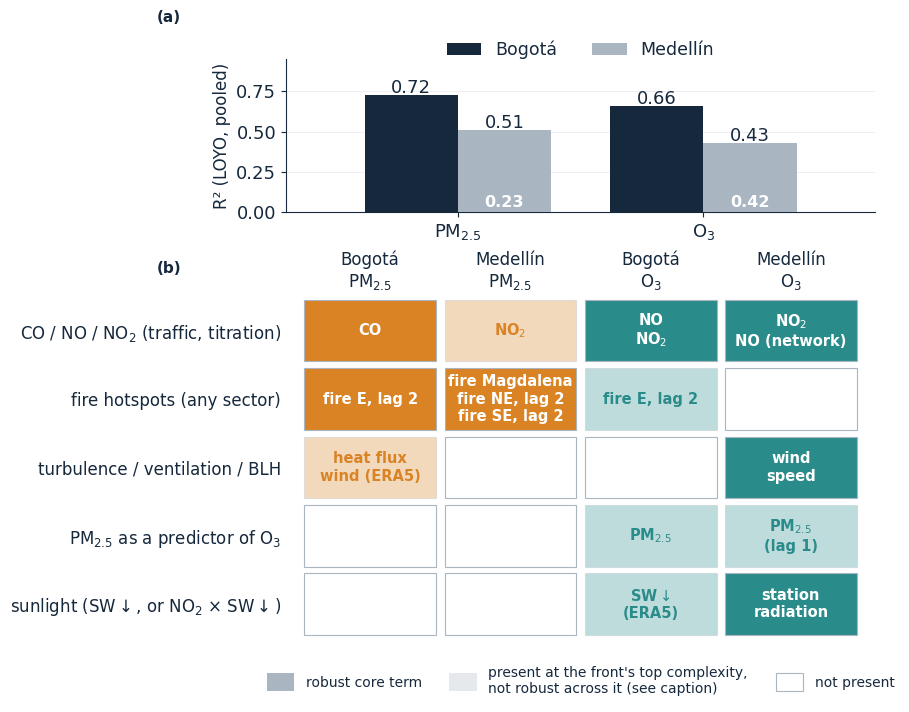

In [5]:
# Figure
fig = plt.figure(figsize=S['figsize'])
gs = fig.add_gridspec(2, 1, height_ratios=list(S['height_ratios']), hspace=S['hspace'])
fig.subplots_adjust(top=S['top_margin'])   # headroom for panel (a)'s rotated y-label + its tag, which clipped without it
# (a)
ax = fig.add_subplot(gs[0])
si = pd.read_csv(DATA_OUT / "SI_metrics_table.csv").set_index(["city", "pollutant", "model"])   # notebook A2
nn_p = si.r2_pooled.xs("neural-net pipeline", level="model"); nn_y = si.r2_mean_of_years.xs("neural-net pipeline", level="model")
vals = {"PM$_{2.5}$": (nn_p[("Bogota", "pm25")], nn_p[("Medellin", "pm25")]), "O$_3$": (nn_p[("Bogota", "o3")], nn_p[("Medellin", "o3")])}
yrs = {"PM$_{2.5}$": (nn_y[("Bogota", "pm25")], nn_y[("Medellin", "pm25")]), "O$_3$": (nn_y[("Bogota", "o3")], nn_y[("Medellin", "o3")])}
x = np.arange(2); w = S['bar_width']
for j, (city, col) in enumerate(CITY_COLOURS.items()):
    v = [vals[p][j] for p in vals]
    ax.bar(x + (j - 0.5) * w, v, w, color=col, label=city, zorder=3)
    for xi, vi in zip(x + (j - 0.5) * w, v): ax.text(xi, vi + 0.012, f"{vi:.2f}", ha="center", fontsize=S['value_fs'])
    if city == "Medellín":                                      # R4: annotate the much lower mean-of-per-year R2, inside the bar
        for xi, p in zip(x + (j - 0.5) * w, vals):
            ax.text(xi, 0.015, f"{yrs[p][j]:.2f}", ha="center", va="bottom", fontsize=S['value_fs'] - 1.5, color="white", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(list(vals), fontsize=S['tick_fs']); ax.set_ylim(0, 0.95)
ax.set_xlim(x[0] - 0.7, x[-1] + 0.7)   # 2026-09-24: default categorical margins left too much dead space either side
ax.set_ylabel("R² (LOYO, pooled)", fontsize=S['fontsize']); ax.tick_params(axis="y", labelsize=S['tick_fs'])
ax.legend(frameon=False, fontsize=S['legend_fs'], loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=2)   # 2026-09-24: moved above the bars, was colliding with the value labels once fonts got bigger
ax.grid(axis="y", color=LIGHT, lw=0.6, zorder=0)
panel_label(ax, "a", x=-0.22, y=1.22)
# (b)
ax = fig.add_subplot(gs[1])
cols = list(cores)
SHORT = {'hotspots_sector_E_lag3': 'fire E\n(3-day lag)', 'photochemical_potential': 'photochem.\npotential', 'dry_stagnation_lag1': 'dry stagn.\n(lag 1)', 'tcwv_lag1': 'TCWV\n(lag 1)', 'no_lag3': 'NO (lag 3)', 'tke_proxy': 'TKE proxy',
         # display names, not raw code identifiers, in the cells (2026-09-23)
         'pm25': 'PM$_{2.5}$', 'co': 'CO', 'no': 'NO', 'no2': 'NO$_2$', 'rh_2m': 'RH', 'blh_max': 'BLH (max)', 'w700': 'w$_{700}$',
         # new Antioquia batch (2026-09-23/24)
         'no_sisaire': 'NO (network)', 'pm25_lag1': 'PM$_{2.5}$\n(lag 1)', 'radiation_station': 'station\nradiation', 'radiation_mean': 'SW$\\downarrow$\n(ERA5)', 'wind_speed': 'wind\nspeed',
         # newly visible now that "present, not robust" cells are shown (2026-09-28)
         'temp_2m': 'T$_{2m}$', 'wind_speed_era5': 'wind (ERA5)', 'ventilation_station': 'ventilation',
         'rh_10m': 'RH (10m)', 'blh_mean': 'BLH (mean)', 'sensible_heat_flux': 'heat flux', 'tcwv': 'TCWV', 'w700_lag3': 'w$_{700}$\n(lag 3)', 'no_lag2': 'NO (lag 2)', 'radiation_station_lag1': 'station rad.\n(lag 1)'}
import re as _re
def short(h):
    if h in SHORT: return SHORT[h]
    m = _re.match(r"hotspots_sector_(\w+?)(?:_lag(\d))?$", h)
    if m: return f"fire {m.group(1)}" + (f", lag {m.group(2)}" if m.group(2) else "")
    m = _re.match(r"hotspots_magdalena_valley(?:_lag(\d))?$", h)
    if m: return "fire Magdalena" + (f", lag {m.group(1)}" if m.group(1) else "")
    return h.replace("_", " ")
for i, (role, vs) in enumerate(ROLES):
    for j, k in enumerate(cols):
        hit = sorted(set(cores[k]) & vs)
        phit = sorted(set(partials[k]) & vs)   # present at the front's top complexity, not robust (see note above)
        colr = PM25 if k[1] == "PM$_{2.5}$" else O3
        fc = colr if hit else (colr if phit else "white")
        ax.add_patch(Rectangle((j - 0.47, i - 0.45), 0.94, 0.90, facecolor=fc, alpha=1.0 if hit else (0.3 if phit else 1.0),
                               edgecolor=S['cell_edge'], lw=S['cell_lw']))
        if hit:
            ax.text(j, i, "\n".join(short(h) for h in hit), ha="center", va="center", fontsize=S['cell_fontsize'] if sum(short(h).count("\n") + 1 for h in hit) <= 3 else S['cell_fontsize'] - 2, color="white", fontweight="bold")
        elif phit:
            ax.text(j, i, "\n".join(short(h) for h in phit), ha="center", va="center", fontsize=S['cell_fontsize'] if sum(short(h).count("\n") + 1 for h in phit) <= 3 else S['cell_fontsize'] - 2, color=colr, fontweight="bold")
ax.set_xlim(-0.6, len(cols) - 0.4); ax.set_ylim(len(ROLES) - 0.5, -0.5)
ax.set_xticks(range(len(cols))); ax.set_xticklabels([f"{c}\n{p}" for c, p in cols], fontsize=S['colhead_fs'])
ax.xaxis.tick_top(); ax.set_yticks(range(len(ROLES))); ax.set_yticklabels([r for r, _ in ROLES], fontsize=S['role_fs'])
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
panel_label(ax, "b", x=-0.22, y=1.06)
h = [Rectangle((0, 0), 1, 1, facecolor=GREY, alpha=1.0, label="robust core term"),
     Rectangle((0, 0), 1, 1, facecolor=GREY, alpha=0.3, label="present at the front's top complexity,\nnot robust across it (see caption)"),
     Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=S['cell_edge'], lw=S['cell_lw'], label="not present")]
ax.legend(handles=h, loc="upper center", bbox_to_anchor=(0.5, -0.045), ncol=3, frameon=False, fontsize=S['role_fs'] - 2, handleheight=1.6)
save_fig(fig, "fig07_medellin_vs_bogota")